# MIT-BIH Heartbeat Classification (binary: Normal vs Abnormal): a hardware-friendly CNN for the DE2-115 accelerator

This notebook trains a **small 1-D CNN** that classifies every heartbeat in the MIT-BIH Arrhythmia
Database as **Normal (N)** or **Abnormal (ABN)**, then exports it in a form that can be implemented in hardware:
int8 weights, integer requantisation constants, a bit-exact integer reference model, a C header and test vectors.

In [1]:

import os, json, math, random
import numpy as np
import wfdb
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from scipy.signal import resample_poly
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.11.0+cu128 | device: cuda


## 1. Configuration

In [2]:
DATA_DIR   = "mitdb"           # MIT-BIH files are downloaded here
EXPORT_DIR = "export_binary"   # output files

FS_IN  = 360                   # MIT-BIH sampling rate
FS     = 200                   # target rate 
ADC_PER_MV = 200               # same scaling as tools/ecg_to_hex.py (MIT-BIH style)
PRE, POST  = 48, 80            # samples before / after the R-peak  -> 0.24 s + 0.40 s
WIN        = PRE + POST        # 128 samples (power of two -> mean = sum >> 7)
MAX_SHIFT  = 4                 # +/- samples of random R-peak jitter during training
                              
RR_HIST      = 8               # short-term RR average over the previous 8 intervals
RR_HIST_LONG = 32              # long-term RR average over the previous 32 intervals

#   N   = normal beats  (AAMI N: N, L, R, e, j)
#   ABN = abnormal      (AAMI S: A, a, J, S   +   AAMI V: V, E   +   AAMI F: F)
AAMI_CLASS = {'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',
              'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',
              'V': 'V', 'E': 'V',
              'F': 'F'}
BINARY = {'N': 'N', 'S': 'ABN', 'V': 'ABN', 'F': 'ABN'}
AAMI = {sym: BINARY[c] for sym, c in AAMI_CLASS.items()}
BEAT_SYMBOLS = set(AAMI) | {'/', 'f', 'Q'}   
CLASSES = ['N', 'ABN']                       # class 1 = abnormal = "positive" class
POS = 1
CLS_IDX = {c: i for i, c in enumerate(CLASSES)}

# Inter-patient split. Paced records 102, 104, 107, 217 are excluded.
DS1 = ['101','106','108','109','112','114','115','116','118','119','122',
       '124','201','203','205','207','208','209','215','220','223','230']
DS2 = ['100','103','105','111','113','117','121','123','200','202','210',
       '212','213','214','219','221','222','228','231','232','233','234']
# Validation = a few DS1 *patients* (used only for early stopping, model selection and bias calibration).
VAL_RECORDS   = ['106', '118', '119', '220']
TRAIN_RECORDS = [r for r in DS1 if r not in VAL_RECORDS]
TEST_RECORDS  = DS2

BATCH_SIZE = 512
EPOCHS     = int(os.environ.get("EPOCHS", 40))
LR         = 1e-3
PATIENCE   = 8
CLASS_WEIGHT_POWER = 1.0       # 1.0 = full inverse frequency, 0 = no weighting

## 2. Download the MIT-BIH Arrhythmia Database

In [25]:
if not os.path.exists(os.path.join(DATA_DIR, "100.hea")):
    print("Downloading MIT-BIH from PhysioNet (~100 MB) ...")
    wfdb.dl_database("mitdb", DATA_DIR)
else:
    print("MIT-BIH already present in", DATA_DIR)
print(sorted(f[:-4] for f in os.listdir(DATA_DIR) if f.endswith(".hea"))[:50])

MIT-BIH already present in mitdb
['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']


## 3. Load records, resample to 200 Hz, extract beats and RR features


In [26]:
def load_record(rec):
    path = os.path.join(DATA_DIR, rec)
    r = wfdb.rdrecord(path)
    ch = r.sig_name.index("MLII") if "MLII" in r.sig_name else 0
    sig = r.p_signal[:, ch]
    sig = sig - np.median(sig)
    x = resample_poly(sig, FS, FS_IN)                         # 360 -> 200 Hz
    x = np.clip(np.round(x * ADC_PER_MV), -2047, 2047).astype(np.int32)
    ann = wfdb.rdann(path, "atr")
    sym = np.array(ann.symbol)
    pos = np.round(np.asarray(ann.sample) * FS / FS_IN).astype(np.int64)
    keep = np.isin(sym, list(BEAT_SYMBOLS))                   # beats only (drop rhythm/noise marks)
    return x, pos[keep], sym[keep]


def rr_features_int(r):
    # Heart-rate-independent integer RR features (x256) for beats 1..n-2
    # (needs a previous and a next beat). Averages use PREVIOUS intervals only.
    n = len(r)
    feats = np.zeros((n, 4), dtype=np.int64)
    hist = []
    for i in range(1, n - 1):
        pre = int(r[i] - r[i - 1]); post = int(r[i + 1] - r[i])
        h  = hist[-RR_HIST:]      or [pre]
        hl = hist[-RR_HIST_LONG:] or [pre]
        avg8, avg32 = sum(h) // len(h), sum(hl) // len(hl)
        feats[i] = ((pre  * 256) // max(avg8, 1),
                    (post * 256) // max(avg8, 1),
                    (pre  * 256) // max(post, 1),
                    (pre  * 256) // max(avg32, 1))
        hist.append(pre)
    return feats


def extract_beats(records):
    X, RR, Y, REC, RPOS = [], [], [], [], []
    m = MAX_SHIFT
    for rec in records:
        x, r, sym = load_record(rec)
        rr = rr_features_int(r)
        for i in range(1, len(r) - 1):
            if sym[i] not in AAMI:                            # Q-class beats are skipped
                continue
            a, b = r[i] - PRE - m, r[i] + POST + m
            if a < 0 or b > len(x):
                continue
            X.append(x[a:b]); RR.append(rr[i]); Y.append(CLS_IDX[AAMI[sym[i]]])
            REC.append(rec); RPOS.append(r[i])
    return (np.array(X, np.int32), np.array(RR, np.int64), np.array(Y, np.int64),
            np.array(REC), np.array(RPOS))


Xtr, RRtr, ytr, rec_tr, _ = extract_beats(TRAIN_RECORDS)
Xva, RRva, yva, rec_va, _ = extract_beats(VAL_RECORDS)
Xte, RRte, yte, rec_te, rpos_te = extract_beats(TEST_RECORDS)

def counts(y): return {c: int((y == i).sum()) for i, c in enumerate(CLASSES)}
print("window shape (with jitter margin):", Xtr.shape[1:])
def aami_counts(recs):        # how the abnormal class is composed (S / V / F)
    from collections import Counter
    c = Counter()
    for rec in recs:
        _, _, sym = load_record(rec)
        c.update(AAMI_CLASS[s] for s in sym[1:-1] if s in AAMI_CLASS)
    return dict(sorted(c.items()))

print("train:", len(ytr), counts(ytr), " AAMI:", aami_counts(TRAIN_RECORDS))
print("val  :", len(yva), counts(yva), " AAMI:", aami_counts(VAL_RECORDS))
print("test :", len(yte), counts(yte), " AAMI:", aami_counts(TEST_RECORDS))

window shape (with jitter margin): (136,)
train: 42637 {'N': 38662, 'ABN': 3975}  AAMI: {'F': 414, 'N': 38662, 'S': 753, 'V': 2808}
val  : 8332 {'N': 7162, 'ABN': 1170}  AAMI: {'N': 7162, 'S': 190, 'V': 980}
test : 49661 {'N': 44218, 'ABN': 5443}  AAMI: {'F': 388, 'N': 44218, 'S': 1836, 'V': 3219}


## 4. Preprocessing: mean removal and standardisation

**Hardware-friendly definition (identical in training, the integer model and the firmware):**

The statistics are computed on the training patients only, then reused for validation, test and hardware.
In hardware the divisions disappear: each one becomes a fixed integer multiply-and-shift in the quantised model.

X_SIGMA = 73.99 ADC units
RR_MU = [257.62 257.62 261.67 257.15]  RR_SD = [130.67 134.94  87.66 131.7 ]  (pre/avg8, post/avg8, pre/post, pre/avg32) x256


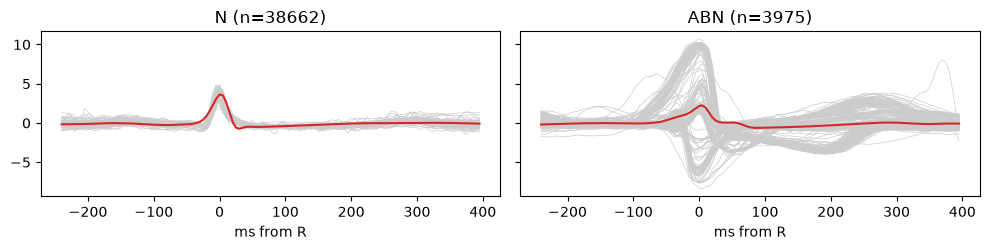

In [27]:
def center_int(w):
    # Mean removal exactly as the hardware does it: floor(sum / 128) via arithmetic shift
    return w - (w.sum(axis=-1, keepdims=True) >> 7)

m = MAX_SHIFT
X_SIGMA = float(center_int(Xtr[:, m:m + WIN]).std())          # global, training set only
RR_MU   = RRtr.mean(axis=0).astype(np.float64)
RR_SD   = RRtr.std(axis=0).astype(np.float64)
print(f"X_SIGMA = {X_SIGMA:.2f} ADC units")
print("RR_MU =", np.round(RR_MU, 2), " RR_SD =", np.round(RR_SD, 2), " (pre/avg8, post/avg8, pre/post, pre/avg32) x256")

# Look at the average beat of each class
fig, ax = plt.subplots(1, len(CLASSES), figsize=(10, 2.6), sharey=True)
t = (np.arange(WIN) - PRE) / FS * 1000
for i, c in enumerate(CLASSES):
    sel = center_int(Xtr[ytr == i][:, m:m + WIN]) / X_SIGMA
    if len(sel):
        ax[i].plot(t, sel[:200].T, color="0.8", lw=0.5); ax[i].plot(t, sel.mean(0), color="C3")
    ax[i].set_title(f"{c} (n={len(sel)})"); ax[i].set_xlabel("ms from R")
plt.tight_layout(); plt.show()

In [28]:
class BeatDataset(Dataset):
    # Returns (standardised beat [1, WIN], standardised RR [4], label).
    # Training: random R-peak jitter, amplitude scaling and noise.
    def __init__(self, X, RR, y, train=False):
        self.X, self.y, self.train = X, y, train
        self.rr = ((RR - RR_MU) / RR_SD).astype(np.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        off = np.random.randint(0, 2 * MAX_SHIFT + 1) if self.train else MAX_SHIFT
        w = center_int(self.X[i, off:off + WIN]).astype(np.float32) / X_SIGMA
        if self.train:
            w = w * np.random.uniform(0.85, 1.15) + np.random.normal(0, 0.03, WIN).astype(np.float32)
        return torch.from_numpy(w[None, :].astype(np.float32)), torch.from_numpy(self.rr[i]), self.y[i]

train_ds = BeatDataset(Xtr, RRtr, ytr, train=True)
val_ds   = BeatDataset(Xva, RRva, yva)
test_ds  = BeatDataset(Xte, RRte, yte)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=2048, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=2048, shuffle=False, num_workers=0)

## 5. Model: a small CNN

```
input  [1 × 128]  standardised beat              rr [4] standardised RR features
Conv1d(1→8,  k=7, pad 3) → BN → ReLU → MaxPool2   → [8 × 64]
Conv1d(8→16, k=5, pad 2) → BN → ReLU → MaxPool2   → [16 × 32]
Conv1d(16→32,k=5, pad 2) → BN → ReLU → MaxPool2   → [32 × 16]
Flatten (channel-major: index = c·16 + t)          → 512
Concat rr                                          → 516
Linear(516→32) → ReLU → Dropout(0.3, training only)
Linear(32→2)  → logits [N, ABN] (argmax = class; no softmax needed in hardware)
```
Convolutions have no bias because BN follows them. At export, BN is folded into conv weights and biases.

In [29]:
class BeatCNN(nn.Module):
    def __init__(self, n_rr=4, n_cls=len(CLASSES)):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 8, 7, padding=3, bias=False);   self.bn1 = nn.BatchNorm1d(8)
        self.conv2 = nn.Conv1d(8, 16, 5, padding=2, bias=False);  self.bn2 = nn.BatchNorm1d(16)
        self.conv3 = nn.Conv1d(16, 32, 5, padding=2, bias=False); self.bn3 = nn.BatchNorm1d(32)
        self.pool  = nn.MaxPool1d(2)
        self.fc1   = nn.Linear(32 * (WIN // 8) + n_rr, 32)
        self.drop  = nn.Dropout(0.3)
        self.fc2   = nn.Linear(32, n_cls)

    def forward(self, x, rr):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = torch.cat([x.flatten(1), rr], dim=1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

model = BeatCNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
L1, L2, L3 = WIN, WIN // 2, WIN // 4
macs = L1*8*1*7 + L2*16*8*5 + L3*32*16*5 + (32*(WIN//8)+4)*32 + 32*len(CLASSES)
print(model)
print(f"parameters: {n_params:,}  |  MACs per beat: {macs:,}  |  int8 weight memory ~ {n_params/1024:.1f} KB")

BeatCNN(
  (conv1): Conv1d(1, 8, kernel_size=(7,), stride=(1,), padding=(3,), bias=False)
  (bn1): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv1d(8, 16, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
  (bn2): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,), bias=False)
  (bn3): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=516, out_features=32, bias=True)
  (drop): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=32, out_features=2, bias=True)
)
parameters: 19,978  |  MACs per beat: 146,624  |  int8 weight memory ~ 19.5 KB


## 6. Training

class weights: {'N': np.float32(0.186), 'ABN': np.float32(1.814)}
epoch  1  loss 0.3374  val F1(ABN) 0.5000
epoch  2  loss 0.1954  val F1(ABN) 0.4757
epoch  3  loss 0.1558  val F1(ABN) 0.3792
epoch  4  loss 0.1417  val F1(ABN) 0.4398
epoch  5  loss 0.1190  val F1(ABN) 0.4715
epoch  6  loss 0.1101  val F1(ABN) 0.4146
epoch  7  loss 0.1102  val F1(ABN) 0.4520
epoch  8  loss 0.1036  val F1(ABN) 0.4162
epoch  9  loss 0.0978  val F1(ABN) 0.4409
early stopping


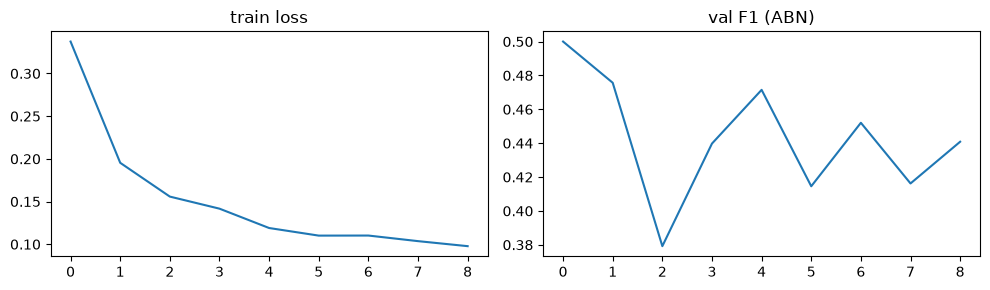

In [30]:
cnt = np.bincount(ytr, minlength=len(CLASSES)).astype(np.float64)
w = (cnt.sum() / (len(CLASSES) * np.maximum(cnt, 1))) ** CLASS_WEIGHT_POWER
class_w = torch.tensor(w / w.mean(), dtype=torch.float32, device=device)
print("class weights:", dict(zip(CLASSES, np.round(class_w.cpu().numpy(), 3))))

criterion = nn.CrossEntropyLoss(weight=class_w)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

def predict(model, loader):
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for x, rr, y in loader:
            P.append(model(x.to(device), rr.to(device)).argmax(1).cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(Y), np.concatenate(P)

os.makedirs(EXPORT_DIR, exist_ok=True)
best_f1, bad, history = -1, 0, []
for epoch in range(1, EPOCHS + 1):
    model.train(); tot = 0.0
    for x, rr, y in train_loader:
        x, rr, y = x.to(device), rr.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x, rr), y)
        loss.backward(); optimizer.step()
        tot += loss.item() * len(y)
    yv, pv = predict(model, val_loader)
    f1 = f1_score(yv, pv, labels=[POS], average="macro", zero_division=0)      # F1 of ABN
    scheduler.step(f1)
    history.append((tot / len(train_ds), f1))
    print(f"epoch {epoch:2d}  loss {tot/len(train_ds):.4f}  val F1(ABN) {f1:.4f}")
    if f1 > best_f1:
        best_f1, bad = f1, 0
        torch.save(model.state_dict(), os.path.join(EXPORT_DIR, "beatcnn_float.pth"))
    else:
        bad += 1
        if bad >= PATIENCE:
            print("early stopping"); break

model.load_state_dict(torch.load(os.path.join(EXPORT_DIR, "beatcnn_float.pth"), map_location=device))
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(h[:, 0]); ax[0].set_title("train loss"); ax[1].plot(h[:, 1]); ax[1].set_title("val F1 (ABN)")
plt.tight_layout(); plt.show()

## 7. Decision-bias calibration and evaluation on DS2 (unseen patients)


best ABN offset on validation: -2.750  (val F1 0.879, without offset 0.500)

===== Float model - DS2 test =====
Se(ABN) 0.481 | Sp 0.998 | +P(ABN) 0.966 | F1(ABN) 0.642 | accuracy 0.941
              precision    recall  f1-score   support

           N      0.940     0.998     0.968     44218
         ABN      0.966     0.481     0.642      5443

    accuracy                          0.941     49661
   macro avg      0.953     0.739     0.805     49661
weighted avg      0.943     0.941     0.932     49661

confusion matrix (rows = true, cols = predicted):
[[44127    91]
 [ 2827  2616]]
  AAMI S:   1836 beats, detected as ABN:   1.0%
  AAMI V:   3219 beats, detected as ABN:  79.0%
  AAMI F:    388 beats, detected as ABN:  14.2%


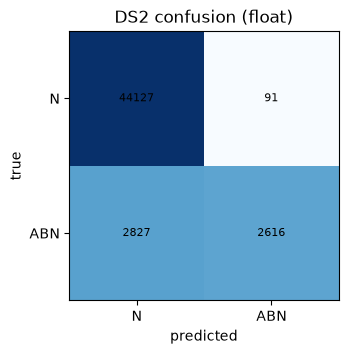

In [31]:
def report(y, p, title):
    print(f"\n===== {title} =====")
    tp = int(((y == POS) & (p == POS)).sum()); fn = int(((y == POS) & (p != POS)).sum())
    tn = int(((y != POS) & (p != POS)).sum()); fp = int(((y != POS) & (p == POS)).sum())
    print(f"Se(ABN) {tp/max(tp+fn,1):.3f} | Sp {tn/max(tn+fp,1):.3f} | +P(ABN) {tp/max(tp+fp,1):.3f} | "
          f"F1(ABN) {2*tp/max(2*tp+fp+fn,1):.3f} | accuracy {(tp+tn)/len(y):.3f}")
    print(classification_report(y, p, labels=list(range(len(CLASSES))), target_names=CLASSES,
                                digits=3, zero_division=0))
    cm = confusion_matrix(y, p, labels=list(range(len(CLASSES))))
    print("confusion matrix (rows = true, cols = predicted):"); print(cm)
    return cm

def logits_of(model, loader):
    model.eval(); out = []
    with torch.no_grad():
        for x, rr, _ in loader:
            out.append(model(x.to(device), rr.to(device)).cpu().numpy())
    return np.concatenate(out)

# calibrate the ABN decision offset on VALIDATION, then fold it into the fc2 bias
LV = logits_of(model, val_loader)
cands = np.arange(-3, 5.001, 0.125)
scores = [f1_score(yva, (LV + np.array([0, d])).argmax(1), labels=[POS], average="macro", zero_division=0) for d in cands]
d_best = float(cands[int(np.argmax(scores))])
print(f"best ABN offset on validation: {d_best:+.3f}  (val F1 {max(scores):.3f}, without offset {scores[list(cands).index(0)]:.3f})")
with torch.no_grad():
    model.fc2.bias[POS] += d_best
torch.save(model.state_dict(), os.path.join(EXPORT_DIR, "beatcnn_float.pth"))   # calibrated weights

yt, pt = predict(model, test_loader)
cm = report(yt, pt, "Float model - DS2 test")

# Which abnormal sub-types (S / V / F) are detected? (uses the original AAMI labels of DS2)
sub = []
for rec in TEST_RECORDS:
    _, r_, sym_ = load_record(rec)
    d = dict(zip(r_.tolist(), sym_.tolist())); sub += [AAMI_CLASS[d[int(p)]] for p in rpos_te[rec_te == rec]]
sub = np.array(sub)
for c in ["S", "V", "F"]:
    m = sub == c
    if m.sum(): print(f"  AAMI {c}: {m.sum():6d} beats, detected as ABN: {(pt[m] == POS).mean()*100:5.1f}%")
plt.figure(figsize=(4, 3.5)); plt.imshow(np.log1p(cm), cmap="Blues")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.xticks(range(len(CLASSES)), CLASSES); plt.yticks(range(len(CLASSES)), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("DS2 confusion (float)"); plt.show()

## 8. Export for hardware

### 8.1 Fold BatchNorm into the convolutions
`w' = w · γ/√(var+ε)`, `b' = β − mean · γ/√(var+ε)`. After this the network contains only conv, ReLU, max-pool and fully-connected layers.

In [33]:
model = model.cpu().eval()

def fold(conv, bn):
    s = bn.weight.detach() / torch.sqrt(bn.running_var + bn.eps)
    W = conv.weight.detach() * s[:, None, None]
    b = bn.bias.detach() - bn.running_mean * s
    return W.numpy().astype(np.float64), b.numpy().astype(np.float64)

FOLD = {}
FOLD["conv1"] = fold(model.conv1, model.bn1)
FOLD["conv2"] = fold(model.conv2, model.bn2)
FOLD["conv3"] = fold(model.conv3, model.bn3)
FOLD["fc1"] = (model.fc1.weight.detach().numpy().astype(np.float64), model.fc1.bias.detach().numpy().astype(np.float64))
FOLD["fc2"] = (model.fc2.weight.detach().numpy().astype(np.float64), model.fc2.bias.detach().numpy().astype(np.float64))

def conv1d_np(x, W, b, pad):            # x [N, Cin, L], W [Cout, Cin, K]
    N, Cin, L = x.shape; K = W.shape[2]
    xp = np.pad(x, ((0, 0), (0, 0), (pad, pad)))
    cols = np.stack([xp[:, :, k:k + L] for k in range(K)], axis=-1)   # [N, Cin, L, K]
    return np.einsum("nclk,ock->nol", cols, W) + b[None, :, None]

def pool2(x): return x.reshape(x.shape[0], x.shape[1], -1, 2).max(-1)

def float_folded_forward(x, rr, keep=False):     # numpy float reference of the folded network
    acts = {"in": x}
    a1 = np.maximum(conv1d_np(x, *FOLD["conv1"], 3), 0); acts["c1"] = a1; a1 = pool2(a1)
    a2 = np.maximum(conv1d_np(a1, *FOLD["conv2"], 2), 0); acts["c2"] = a2; a2 = pool2(a2)
    a3 = np.maximum(conv1d_np(a2, *FOLD["conv3"], 2), 0); acts["c3"] = a3; a3 = pool2(a3)
    cat = np.concatenate([a3.reshape(len(a3), -1), rr], 1); acts["cat"] = cat
    h = np.maximum(cat @ FOLD["fc1"][0].T + FOLD["fc1"][1], 0); acts["fc1"] = h
    out = h @ FOLD["fc2"][0].T + FOLD["fc2"][1]; acts["out"] = out
    return (out, acts) if keep else out

def std_inputs(X, RR):                       # X with jitter margin -> centred window
    w = center_int(X[:, MAX_SHIFT:MAX_SHIFT + WIN]).astype(np.float64) / X_SIGMA
    return w[:, None, :], (RR - RR_MU) / RR_SD

xs, rrs = std_inputs(Xte[:2000], RRte[:2000])
with torch.no_grad():
    ref = model(torch.tensor(xs, dtype=torch.float32), torch.tensor(rrs, dtype=torch.float32)).numpy()
print("max |torch - folded numpy| =", np.abs(ref - float_folded_forward(xs, rrs)).max())

max |torch - folded numpy| = 8.787060048476292e-07


### 8.2 Quantise to int8

* **Weights:** symmetric int8, one scale per output channel: `s_w[c] = max|W_c| / 127`.
* **Activations:** symmetric int8, one scale per tensor, calibrated on training beats (99.99th percentile).
  The RR features share the scale of the flattened conv-3 output so that they can simply be concatenated.
* **Bias:** int32 at scale `s_w[c]·s_in`.
* **Requantisation** of every layer and channel: `y = clamp((acc · M + 2^(sh−1)) >> sh)`, where `M·2^−sh ≈ s_w[c]·s_in / s_out`,
  `M` is a 16-bit integer in [2^14, 2^15) and `>>` is an arithmetic shift. `acc · M` needs up to 48 bits.
  ReLU layers clamp to [0, 127] and the others to [−128, 127]. The last layer keeps 16-bit logits.
* **Input:** `q_in = clamp((xc · M_in + 2^(sh_in−1)) >> sh_in)` with `M_in·2^−sh_in ≈ 1/(σ_x · s_in)`. This is the standardisation step.
* **RR:** `q_rr[i] = clamp(((rr[i] − μ_i) · M_rr[i] + 2^(sh−1)) >> sh)` with integer `μ_i`.

In [34]:
def to_mult_shift(m):
    # Real multiplier m -> (M, sh) with M in [2^14, 2^15) and m ~= M / 2^sh
    m = np.atleast_1d(np.asarray(m, dtype=np.float64))
    sh = (14 - np.floor(np.log2(m))).astype(np.int64)
    M = np.round(m * (2.0 ** sh)).astype(np.int64)
    over = M >= (1 << 15); M[over] //= 2; sh[over] -= 1
    assert (sh >= 1).all() and (sh <= 62).all()
    return M, sh

# ---- calibration on training beats
cal_idx = np.random.RandomState(0).choice(len(ytr), size=min(20000, len(ytr)), replace=False)
xc_, rc_ = std_inputs(Xtr[cal_idx], RRtr[cal_idx])
_, A = float_folded_forward(xc_, rc_, keep=True)
pct = lambda a: float(np.percentile(np.abs(a), 99.99))
S = {"in": pct(A["in"]) / 127, "c1": pct(A["c1"]) / 127, "c2": pct(A["c2"]) / 127,
     "cat": pct(A["cat"]) / 127, "fc1": pct(A["fc1"]) / 127}
S["out"] = np.abs(A["out"]).max() * 2 / 32767          # 16-bit logits with 2x headroom
print({k: round(v, 6) for k, v in S.items()})

Q = {}   # everything the hardware needs
def quant_layer(name, s_in, s_out, relu, out_bits=8):
    W, b = FOLD[name]
    Wc = W.reshape(W.shape[0], -1)
    s_w = np.maximum(np.abs(Wc).max(1), 1e-12) / 127
    Wq = np.clip(np.round(W / s_w.reshape((-1,) + (1,) * (W.ndim - 1))), -127, 127).astype(np.int64)
    Bq = np.round(b / (s_w * s_in)).astype(np.int64)
    M, sh = to_mult_shift(s_w * s_in / s_out)
    lo, hi = (0, 127) if relu else ((-128, 127) if out_bits == 8 else (-32768, 32767))
    Q[name] = dict(W=Wq, B=Bq, M=M, sh=sh, lo=lo, hi=hi)

quant_layer("conv1", S["in"],  S["c1"],  relu=True)
quant_layer("conv2", S["c1"],  S["c2"],  relu=True)
quant_layer("conv3", S["c2"],  S["cat"], relu=True)
quant_layer("fc1",   S["cat"], S["fc1"], relu=True)
quant_layer("fc2",   S["fc1"], S["out"], relu=False, out_bits=16)

Q["in"] = dict(zip(("M", "sh"), [v[0] for v in to_mult_shift(1.0 / (X_SIGMA * S["in"]))]))
RR_MU_INT = np.round(RR_MU).astype(np.int64)
M_rr, sh_rr = to_mult_shift(1.0 / (RR_SD * S["cat"]))
Q["rr"] = dict(mu=RR_MU_INT, M=M_rr, sh=sh_rr)
for k in ("conv1", "conv2", "conv3", "fc1", "fc2"):
    print(f"{k:5s} W{list(Q[k]['W'].shape)}  M range [{Q[k]['M'].min()},{Q[k]['M'].max()}]  "
          f"sh range [{Q[k]['sh'].min()},{Q[k]['sh'].max()}]  |B|max {np.abs(Q[k]['B']).max()}")
print("input M/sh:", Q["in"], "| RR mu/M/sh:", Q["rr"])

{'in': 0.07268, 'c1': 0.067171, 'c2': 0.067565, 'cat': 0.072828, 'fc1': 0.062532, 'out': np.float64(0.000703)}
conv1 W[8, 1, 7]  M range [16867,31797]  sh range [20,23]  |B|max 89
conv2 W[16, 8, 5]  M range [16667,31970]  sh range [22,24]  |B|max 4075
conv3 W[32, 16, 5]  M range [16450,31887]  sh range [22,24]  |B|max 5019
fc1   W[32, 516]  M range [16832,31828]  sh range [24,26]  |B|max 1087
fc2   W[2, 32]  M range [18825,21041]  sh range [17,17]  |B|max 26128
input M/sh: {'M': np.int64(24372), 'sh': np.int64(17)} | RR mu/M/sh: {'mu': array([258, 258, 262, 257]), 'M': array([27547, 26675, 20530, 27330]), 'sh': array([18, 18, 17, 18])}


### 8.3 Bit-exact integer reference model

This function is the **specification** for the hardware and the firmware. The RTL and the C code must reproduce
every intermediate value exactly (int64 arithmetic, `>>` = arithmetic shift, i.e. floor).

In [35]:
def rq(acc, M, sh, lo, hi):
    # requantise: clamp((acc*M + 2^(sh-1)) >> sh); M, sh broadcast per output channel
    return np.clip((acc * M + (np.int64(1) << (sh - 1))) >> sh, lo, hi)

def int_conv(q, L, pad):                     # q [N, Cin, Lin] int64
    W, B = L["W"], L["B"]
    Lin = q.shape[2]; K = W.shape[2]
    qp = np.pad(q, ((0, 0), (0, 0), (pad, pad)))
    acc = np.zeros((q.shape[0], W.shape[0], Lin), np.int64) + B[None, :, None]
    for k in range(K):
        acc += np.einsum("ncl,oc->nol", qp[:, :, k:k + Lin], W[:, :, k])
    return rq(acc, L["M"][None, :, None], L["sh"][None, :, None], L["lo"], L["hi"])

def int_pool2(q): return q.reshape(q.shape[0], q.shape[1], -1, 2).max(-1)

def int_forward(W128, RR, keep=False):
    # W128: [N, 128] raw ADC window (R at index PRE); RR: [N, 4] integer RR features
    W128 = W128.astype(np.int64); RR = RR.astype(np.int64)
    xc = W128 - (W128.sum(1, keepdims=True) >> 7)                       # mean removal
    q0 = rq(xc, Q["in"]["M"], Q["in"]["sh"], -128, 127)[:, None, :]    # standardise + quantise
    qrr = rq(RR - Q["rr"]["mu"], Q["rr"]["M"], Q["rr"]["sh"], -128, 127)
    c1 = int_conv(q0, Q["conv1"], 3);  p1 = int_pool2(c1)
    c2 = int_conv(p1, Q["conv2"], 2);  p2 = int_pool2(c2)
    c3 = int_conv(p2, Q["conv3"], 2);  p3 = int_pool2(c3)
    cat = np.concatenate([p3.reshape(len(p3), -1), qrr], 1)            # channel-major flatten
    L1 = Q["fc1"]; h = rq(cat @ L1["W"].T + L1["B"], L1["M"], L1["sh"], L1["lo"], L1["hi"])
    L2 = Q["fc2"]; out = rq(h @ L2["W"].T + L2["B"], L2["M"], L2["sh"], L2["lo"], L2["hi"])
    pred = out.argmax(1)
    if keep:
        return pred, dict(q0=q0[:, 0], qrr=qrr, p1=p1, p2=p2, p3=p3, cat=cat, fc1=h, logits=out)
    return pred

def int_predict(X, RR, bs=4096):
    return np.concatenate([int_forward(X[i:i + bs, MAX_SHIFT:MAX_SHIFT + WIN], RR[i:i + bs])
                           for i in range(0, len(X), bs)])

pi = int_predict(Xte, RRte)
print(f"int8 vs float agreement on DS2: {(pi == pt).mean()*100:.2f}%")
cm_int = report(yt, pi, "INT8 integer model - DS2 test")
print("F1(ABN) float %.4f | int8 %.4f" % (f1_score(yt, pt, labels=[POS], average='macro'),
                                            f1_score(yt, pi, labels=[POS], average='macro')))

int8 vs float agreement on DS2: 99.95%

===== INT8 integer model - DS2 test =====
Se(ABN) 0.479 | Sp 0.998 | +P(ABN) 0.966 | F1(ABN) 0.640 | accuracy 0.941
              precision    recall  f1-score   support

           N      0.940     0.998     0.968     44218
         ABN      0.966     0.479     0.640      5443

    accuracy                          0.941     49661
   macro avg      0.953     0.738     0.804     49661
weighted avg      0.943     0.941     0.932     49661

confusion matrix (rows = true, cols = predicted):
[[44127    91]
 [ 2837  2606]]
F1(ABN) float 0.6420 | int8 0.6403


### 8.4 Write the hardware files

In [36]:
os.makedirs(os.path.join(EXPORT_DIR, "hex"), exist_ok=True)
os.makedirs(os.path.join(EXPORT_DIR, "test_vectors"), exist_ok=True)
LAYERS = ["conv1", "conv2", "conv3", "fc1", "fc2"]

def write_hex(path, arr, bits):
    mask = (1 << bits) - 1; digits = bits // 4
    with open(path, "w") as f:
        for v in np.asarray(arr).ravel():
            f.write(f"{int(v) & mask:0{digits}x}\n")

for L in LAYERS:
    write_hex(f"{EXPORT_DIR}/hex/{L}_w.hex", Q[L]["W"], 8)
    write_hex(f"{EXPORT_DIR}/hex/{L}_b.hex", Q[L]["B"], 32)
    write_hex(f"{EXPORT_DIR}/hex/{L}_m.hex", Q[L]["M"], 16)
    write_hex(f"{EXPORT_DIR}/hex/{L}_sh.hex", Q[L]["sh"], 8)

np.savez(f"{EXPORT_DIR}/beatcnn_int8.npz", **{f"{L}_{k}": Q[L][k] for L in LAYERS for k in ("W", "B", "M", "sh")},
         in_M=Q["in"]["M"], in_sh=Q["in"]["sh"], rr_mu=Q["rr"]["mu"], rr_M=Q["rr"]["M"], rr_sh=Q["rr"]["sh"])

meta = {
    "classes": CLASSES, "fs_hz": FS, "adc_per_mv": ADC_PER_MV, "window": WIN, "pre": PRE, "post": POST,
    "rr_hist": [RR_HIST, RR_HIST_LONG],
    "rr_features": ["pre*256//avg8", "post*256//avg8", "pre*256//post", "pre*256//avg32"],
    "rr_note": "avg8/avg32 = integer mean of the PREVIOUS 8/32 RR intervals (current beat excluded)",
    "abn_bias_offset": d_best,
    "x_sigma": X_SIGMA, "rr_mu": RR_MU.tolist(), "rr_sd": RR_SD.tolist(),
    "act_scales": {k: float(v) for k, v in S.items()},
    "input": {"M": int(Q["in"]["M"]), "sh": int(Q["in"]["sh"])},
    "rr": {k: [int(x) for x in Q["rr"][k]] for k in ("mu", "M", "sh")},
    "layers": {L: {"shape": list(Q[L]["W"].shape), "lo": Q[L]["lo"], "hi": Q[L]["hi"],
                   "pad": {"conv1": 3, "conv2": 2, "conv3": 2}.get(L, 0),
                   "maxpool2": L.startswith("conv"), "relu": L != "fc2"} for L in LAYERS},
    "flatten_order": "channel-major: cat[c*16 + t] for conv3 pooled output, then 4 RR features",
    "requant": "y = clamp((acc*M + (1<<(sh-1))) >> sh, lo, hi), arithmetic shift, acc*M needs 48 bits",
    "mean_removal": "xc = w - (sum(w) >> 7)",
}
json.dump(meta, open(f"{EXPORT_DIR}/quant_params.json", "w"), indent=2)

# C header for the firmware / software baseline
def c_arr(name, arr, ctype):
    vals = ", ".join(str(int(v)) for v in np.asarray(arr).ravel())
    return f"static const {ctype} {name}[{np.asarray(arr).size}] = {{{vals}}};\n"
with open(f"{EXPORT_DIR}/beatcnn_params.h", "w") as f:
    f.write("// Auto-generated by the MIT-BIH training notebook - int8 BeatCNN\n#pragma once\n#include <stdint.h>\n\n")
    f.write(f"#define BC_WIN {WIN}\n#define BC_PRE {PRE}\n#define BC_NCLS {len(CLASSES)}\n")
    f.write(f"#define BC_IN_M {int(Q['in']['M'])}\n#define BC_IN_SH {int(Q['in']['sh'])}\n")
    f.write("// classes: " + ", ".join(f"{i}={c}" for i, c in enumerate(CLASSES)) + "\n")
    f.write(c_arr("BC_RR_MU", Q["rr"]["mu"], "int32_t") + c_arr("BC_RR_M", Q["rr"]["M"], "int32_t")
            + c_arr("BC_RR_SH", Q["rr"]["sh"], "int8_t"))
    for L in LAYERS:
        Lu = L.upper()
        f.write(f"\n// {L}: W{list(Q[L]['W'].shape)}  out clamp [{Q[L]['lo']},{Q[L]['hi']}]\n")
        f.write(c_arr(f"BC_{Lu}_W", Q[L]["W"], "int8_t") + c_arr(f"BC_{Lu}_B", Q[L]["B"], "int32_t")
                + c_arr(f"BC_{Lu}_M", Q[L]["M"], "int32_t") + c_arr(f"BC_{Lu}_SH", Q[L]["sh"], "int8_t"))

# test vectors: up to 16 beats of each class from DS2
sel = np.concatenate([np.where(yte == i)[0][:16] for i in range(len(CLASSES))])
Wv, RRv = Xte[sel, MAX_SHIFT:MAX_SHIFT + WIN], RRte[sel]
pv, tv = int_forward(Wv, RRv, keep=True)
np.savez(f"{EXPORT_DIR}/test_vectors/vectors.npz", window=Wv, rr=RRv, label=yte[sel], pred=pv,
         record=rec_te[sel], rpos=rpos_te[sel], **tv)
write_hex(f"{EXPORT_DIR}/test_vectors/window.hex", Wv, 16)        # 128 x int16 per beat
write_hex(f"{EXPORT_DIR}/test_vectors/rr.hex", RRv, 32)           # 4 x int32 per beat
write_hex(f"{EXPORT_DIR}/test_vectors/label.hex", yte[sel], 8)
write_hex(f"{EXPORT_DIR}/test_vectors/logits.hex", tv["logits"], 16)
write_hex(f"{EXPORT_DIR}/test_vectors/pred.hex", pv, 8)
for k in ("q0", "p1", "p2", "p3", "fc1"):
    write_hex(f"{EXPORT_DIR}/test_vectors/{k}.hex", tv[k], 8)
print(f"{len(sel)} test vectors written; int model correct on {np.mean(pv == yte[sel])*100:.0f}% of them")
for root, _, files in os.walk(EXPORT_DIR):
    for fn in sorted(files):
        p = os.path.join(root, fn); print(f"  {p:45s} {os.path.getsize(p):>9,d} B")

32 test vectors written; int model correct on 50% of them
  export_binary\beatcnn_float.pth                  87,280 B
  export_binary\beatcnn_int8.npz                  167,054 B
  export_binary\beatcnn_params.h                   90,064 B
  export_binary\quant_params.json                   2,347 B
  export_binary\hex\conv1_b.hex                        80 B
  export_binary\hex\conv1_m.hex                        48 B
  export_binary\hex\conv1_sh.hex                       32 B
  export_binary\hex\conv1_w.hex                       224 B
  export_binary\hex\conv2_b.hex                       160 B
  export_binary\hex\conv2_m.hex                        96 B
  export_binary\hex\conv2_sh.hex                       64 B
  export_binary\hex\conv2_w.hex                     2,560 B
  export_binary\hex\conv3_b.hex                       320 B
  export_binary\hex\conv3_m.hex                       192 B
  export_binary\hex\conv3_sh.hex                      128 B
  export_binary\hex\conv3_w.hex           

### 8.5 Optional: ONNX export (for Netron visualisation or other toolflows)

In [37]:
try:
    dummy = (torch.zeros(1, 1, WIN), torch.zeros(1, 4))
    torch.onnx.export(model, dummy, f"{EXPORT_DIR}/beatcnn_float.onnx", input_names=["beat", "rr"],
                      output_names=["logits"], opset_version=13)
    print("ONNX written")
except Exception as e:
    print("ONNX export skipped:", e)

ONNX written
